# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> YMLS Uzbekistan, ML Fundamentals, fall 2026 <a class="tocSkip">

# Week 2 seminar. Linear regression: from likelihood to least squares

Maximum likelihood by hand on a coin and on a melon. Then linear regression on flats in Tashkent: the normal equations, the reason the loss is the squared error, and gradient descent from scratch. At the end, scikit-learn on medical data with ten features.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/girafe-ai/ml-course/blob/26f_ymls_uz/week0_02_mle_and_linear_regression/week0_02_01_linear_regression__completed.ipynb)

This week's [lecture slides](https://github.com/girafe-ai/ml-course/blob/26f_ymls_uz/week0_02_mle_and_linear_regression/ml-basic_lect02_mle_linear_regression.pdf) are in the same folder. The links to the interactive pages are in the course chat.

_YMLS Uzbekistan, ML Fundamentals, fall 2026_

_Completed version with solutions and outputs. The student version is `week0_02_01_linear_regression.ipynb`._

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy import optimize, stats
from sklearn.datasets import load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


SEED = 42  # one seed for every split and random generator

# Plot style: gray axes, colour only for data
INK, INK2, INK3, LINE = "#1D1D1F", "#6E6E73", "#86868B", "#D2D2D7"
ACCENT, ORANGE, GREEN, PURPLE = "#0071E3", "#FF9F0A", "#34C759", "#AF52DE"
plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 13,
        "mathtext.fontset": "cm",
        "axes.edgecolor": LINE,
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
        "axes.prop_cycle": plt.cycler(color=[ACCENT, ORANGE, GREEN, PURPLE, INK3]),
        "xtick.color": INK3,
        "ytick.color": INK3,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "xtick.major.size": 0,
        "ytick.major.size": 0,
        "xtick.minor.size": 0,
        "ytick.minor.size": 0,
        "legend.frameon": False,
        "legend.fontsize": 11,
        "lines.linewidth": 2.2,
        "lines.markersize": 6,
        "figure.facecolor": "white",
    }
)

## 1. Maximum likelihood by hand

### 1.1 A coin

A coin lands heads with an unknown probability $\theta$. We flip it $n = 10$ times and see $k = 7$ heads. The flips are independent, so the probability of the whole sequence is a product, and its logarithm is a sum:

$$L(\theta) = \theta^{k} (1 - \theta)^{n - k}, \qquad l(\theta) = \log L(\theta) = k \log \theta + (n - k) \log (1 - \theta).$$

The data is fixed and $\theta$ varies. The maximum likelihood estimate $\hat\theta$ is the value of $\theta$ where $L$ is largest.

In [2]:
flips = np.array([1, 1, 0, 1, 1, 1, 0, 1, 0, 1])  # 1 = heads, 0 = tails
print(f"{len(flips)} flips, {flips.sum()} heads")

10 flips, 7 heads


**Exercise 1.1.** Write `log_likelihood(theta, flips)`: the log-likelihood $l(\theta)$ of a sequence of flips.

In [3]:
def log_likelihood(theta, flips):
    """Log-likelihood l(theta) of coin flips (1 = heads, 0 = tails) for heads probability theta."""
    n_heads = flips.sum()
    n_tails = len(flips) - n_heads
    return n_heads * np.log(theta) + n_tails * np.log(1 - theta)

In [4]:
l_07, l_05 = log_likelihood(0.7, flips), log_likelihood(0.5, flips)
assert l_07 is not None, "Fill in log_likelihood above"
assert np.isclose(l_07, np.log(0.7**7 * 0.3**3)), "At theta = 0.7 expect log(0.7^7 * 0.3^3)"
assert np.isclose(l_05, 10 * np.log(0.5)), "At theta = 0.5 expect 10 * log(0.5)"
print(f"l(0.7) = {l_07:.3f}, so L(0.7) = {np.exp(l_07):.5f}")
print(f"l(0.5) = {l_05:.3f}, so L(0.5) = {np.exp(l_05):.5f}")

l(0.7) = -6.109, so L(0.7) = 0.00222
l(0.5) = -6.931, so L(0.5) = 0.00098


The data is more than twice as likely under $\theta = 0.7$ as under a fair coin. Now try 99 values of $\theta$ and take the best one.

argmax on the grid: 0.70, k / n = 0.70


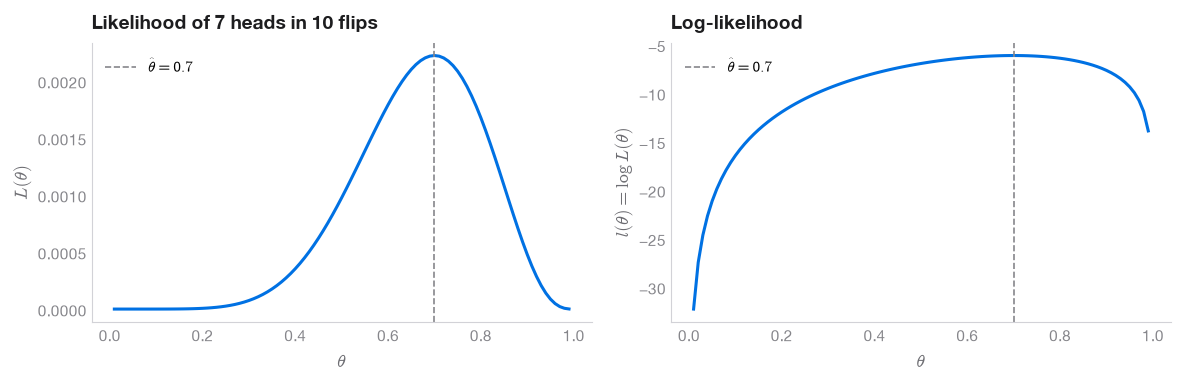

In [5]:
assert log_likelihood(0.5, flips) is not None, "Finish Exercise 1.1 first"
theta_grid = np.linspace(0.01, 0.99, 99)  # 0.01, 0.02, ..., 0.99
log_lik = np.array([log_likelihood(theta, flips) for theta in theta_grid])
theta_hat = theta_grid[log_lik.argmax()]
print(f"argmax on the grid: {theta_hat:.2f}, k / n = {flips.mean():.2f}")

fig, (ax_lik, ax_log) = plt.subplots(1, 2, figsize=(12, 4))
ax_lik.plot(theta_grid, np.exp(log_lik), color=ACCENT)
ax_lik.set(xlabel=r"$\theta$", ylabel=r"$L(\theta)$", title="Likelihood of 7 heads in 10 flips")
ax_log.plot(theta_grid, log_lik, color=ACCENT)
ax_log.set(xlabel=r"$\theta$", ylabel=r"$l(\theta) = \log L(\theta)$", title="Log-likelihood")
for ax in (ax_lik, ax_log):
    ax.axvline(theta_hat, color=INK3, ls="--", lw=1.2, label=rf"$\hat\theta = {theta_hat:.1f}$")
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Both curves peak at the same $\theta$, because the logarithm is an increasing function. The peak is at $k / n = 0.7$, the share of heads in the data, which is what the derivative gives in the lecture. On the interactive page `01_likelihood_coin.html` you can flip more coins and see what happens to the curve.

Why take the logarithm at all? Flip the coin 5,000 times and compute both versions.

In [6]:
rng = np.random.default_rng(SEED)
many_flips = (rng.random(5000) < 0.7).astype(int)  # 5,000 flips of a coin with theta = 0.7
p_each = np.where(many_flips == 1, 0.7, 0.3)  # probability of every single flip at theta = 0.7

print("likelihood, a product of 5,000 numbers:", np.prod(p_each))
print("log-likelihood, a sum of 5,000 logs:   ", np.log(p_each).sum().round(1))

likelihood, a product of 5,000 numbers: 0.0
log-likelihood, a sum of 5,000 logs:    -3030.6


The true product is about $e^{-3031}$. The smallest positive number a float can hold is about $10^{-323}$, so the product is rounded to exactly 0.0. That happens for every $\theta$, and there is nothing left to maximise. The sum of logarithms is an ordinary number. For this reason we maximise the log-likelihood, or minimise the negative log-likelihood (NLL), which is the same thing.

### 1.2 A melon on market scales

A seller puts the same melon on the scales six times. Each reading is the true weight plus a small error, so we treat the readings as independent draws from $\mathcal{N}(\mu, \sigma^2)$. Which $\mu$ and $\sigma$ make these six numbers most likely?

In [7]:
weights = np.array([4.9, 5.2, 5.0, 5.3, 4.8, 5.1])  # kg, six readings of one melon

**Exercise 1.2.** Write `normal_log_likelihood(mu, sigma, x)`: the sum of the log-densities of all readings. `stats.norm.logpdf(x, loc=mu, scale=sigma)` returns the log-density of each reading.

In [8]:
def normal_log_likelihood(mu, sigma, x):
    """Log-likelihood of the sample x under N(mu, sigma^2)."""
    return stats.norm.logpdf(x, loc=mu, scale=sigma).sum()

In [9]:
value = normal_log_likelihood(5.0, 0.2, weights)
assert value is not None, "Fill in normal_log_likelihood above"
# the formula from the lecture: -n log(sigma sqrt(2 pi)) - sum((x - mu)^2) / (2 sigma^2)
by_formula = -6 * np.log(0.2 * np.sqrt(2 * np.pi)) - ((weights - 5.0) ** 2).sum() / (2 * 0.2**2)
assert np.isclose(value, by_formula), "Sum the log-densities of all six readings"
print(f"l(mu = 5.0, sigma = 0.2) = {value:.3f}")

l(mu = 5.0, sigma = 0.2) = 1.768


`scipy.optimize.minimize` searches for the minimum of a function numerically. Give it the NLL and compare its answer with the formulas from the lecture:

$$\hat\mu = \frac{1}{n} \sum_{i=1}^{n} x_i, \qquad \hat\sigma^2 = \frac{1}{n} \sum_{i=1}^{n} (x_i - \hat\mu)^2.$$

optimiser:     mu = 5.050 kg, sigma = 0.171 kg
formulas:      mu = 5.050 kg, sigma = 0.171 kg (divides by n)
with n - 1:    sigma = 0.187 kg


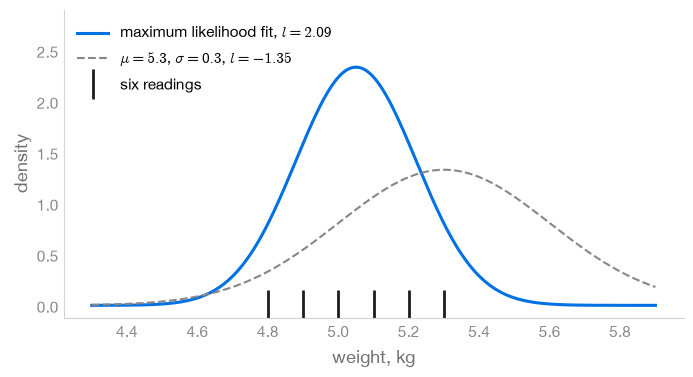

In [10]:
assert normal_log_likelihood(5.0, 0.2, weights) is not None, "Finish Exercise 1.2 first"


def melon_nll(params):
    """Negative log-likelihood of the six readings; params = (mu, sigma)."""
    mu, sigma = params
    return -normal_log_likelihood(mu, sigma, weights)


melon_mu, melon_sigma = optimize.minimize(melon_nll, x0=[5.0, 0.5], method="Nelder-Mead").x

print(f"optimiser:     mu = {melon_mu:.3f} kg, sigma = {melon_sigma:.3f} kg")
print(f"formulas:      mu = {weights.mean():.3f} kg, sigma = {weights.std():.3f} kg (divides by n)")
print(f"with n - 1:    sigma = {weights.std(ddof=1):.3f} kg")

x_grid = np.linspace(4.3, 5.9, 300)
fit_l = normal_log_likelihood(melon_mu, melon_sigma, weights)
other_l = normal_log_likelihood(5.3, 0.3, weights)  # a worse candidate, for comparison
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    x_grid,
    stats.norm.pdf(x_grid, melon_mu, melon_sigma),
    color=ACCENT,
    label=rf"maximum likelihood fit, $l = {fit_l:.2f}$",
)
ax.plot(
    x_grid,
    stats.norm.pdf(x_grid, 5.3, 0.3),
    color=INK3,
    ls="--",
    lw=1.5,
    label=rf"$\mu = 5.3$, $\sigma = 0.3$, $l = {other_l:.2f}$",
)
ax.plot(weights, np.zeros(len(weights)), "|", color=INK, ms=22, mew=2, label="six readings")
ax.set(xlabel="weight, kg", ylabel="density", ylim=(-0.12, 2.9))
ax.legend(loc="upper left")
plt.show()

The optimiser lands on the sample mean, 5.05 kg, and on the standard deviation that divides by $n$, 0.171 kg. This estimate of $\sigma$ is a little too small on average. Dividing by $n - 1$ removes the bias and gives 0.187 kg. Watch the defaults: `np.std` divides by $n$, `pandas` divides by $n - 1$. On the page `02_fit_a_normal.html` you can drag the bell over the same six readings by hand.

## 2. Flats in Tashkent: one feature

Forty flats, each with an area in m² and a price in thousand US dollars. The data is synthetic: price $= 15 + 1.1 \cdot$ area $+\ \varepsilon$ with noise $\varepsilon \sim \mathcal{N}(0, 12^2)$. We know the true line, so we can see how close the estimates get.

area:  [ 89 119  50  32 109] ...
price: [124.1 158.7  82.5  29.3 141.5] ...


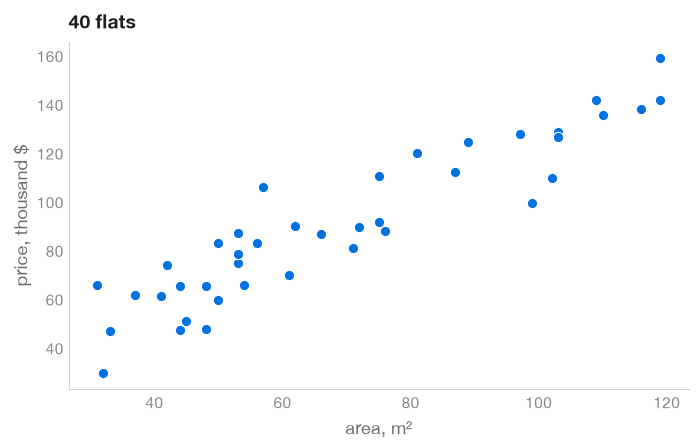

In [11]:
rng = np.random.default_rng(2038)
area = np.round(rng.uniform(30, 120, 40)).astype(int)  # m²
price = np.round(15 + 1.1 * area + rng.normal(0, 12, 40), 1)  # thousand US dollars

print("area: ", area[:5], "...")
print("price:", price[:5], "...")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(area, price, s=55, color=ACCENT, edgecolor="white", linewidth=0.8)
ax.set(xlabel="area, m²", ylabel="price, thousand $", title="40 flats")
plt.show()

### 2.1 The normal equations

A linear model predicts $\hat y = b + w x$: the intercept $b$ plus the weight $w$ times the area. Put a column of ones next to the areas and call the result $X$. Then all 40 predictions are one product, $\hat y = X \mathbf{w}$ with $\mathbf{w} = (b, w)$.

The loss is the mean squared error, $L(\mathbf{w}) = \frac{1}{n} \lVert y - X \mathbf{w} \rVert^2$. Its gradient is zero where the normal equations hold:

$$X^\top X \, \mathbf{w} = X^\top y.$$

**Exercise 2.1.** Build the design matrix `X` (a column of ones, then the area) and solve the normal equations with `np.linalg.solve`. Do not compute the inverse of $X^\top X$: solving the system is faster and loses less precision.

In [12]:
X = np.column_stack([np.ones(len(area)), area])  # shape (40, 2): ones, then the area
w_hat = np.linalg.solve(X.T @ X, X.T @ price)  # solves (X^T X) w = X^T y

In [13]:
assert X is not None and w_hat is not None, "Fill in X and w_hat above"
assert X.shape == (40, 2) and np.all(X[:, 0] == 1), "X needs a column of ones, then the area"
assert np.allclose(w_hat, [14.525, 1.0973], atol=1e-3), "w_hat should solve (X^T X) w = X^T y"
print(f"b = {w_hat[0]:.2f} thousand dollars, w = {w_hat[1]:.3f} thousand dollars per m²")

b = 14.53 thousand dollars, w = 1.097 thousand dollars per m²


NumPy and scikit-learn have their own least squares solvers. `np.linalg.lstsq` takes the same `X`. `LinearRegression` takes the features without the column of ones and adds the intercept itself.

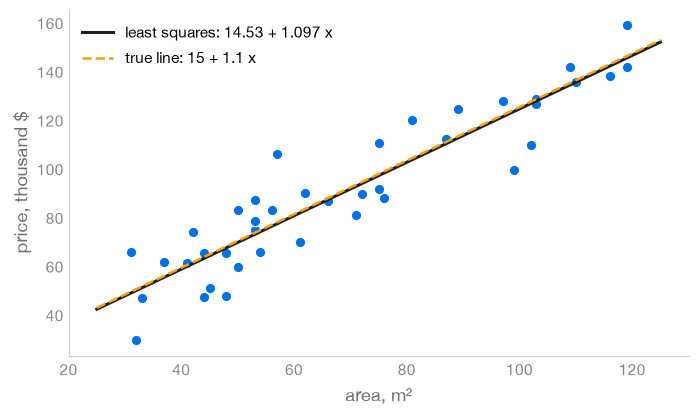

,b,w
normal equations,14.525,1.0973
np.linalg.lstsq,14.525,1.0973
sklearn LinearRegression,14.525,1.0973


In [14]:
assert w_hat is not None, "Finish Exercise 2.1 first"
b_hat, slope_hat = w_hat  # the intercept and the weight of the area, used below
w_lstsq = np.linalg.lstsq(X, price, rcond=None)[0]
flat_model = LinearRegression().fit(area.reshape(-1, 1), price)

x_line = np.array([25, 125])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(area, price, s=55, color=ACCENT, edgecolor="white", linewidth=0.8)
ax.plot(
    x_line,
    b_hat + slope_hat * x_line,
    color=INK,
    label=f"least squares: {b_hat:.2f} + {slope_hat:.3f} x",
)
ax.plot(x_line, 15 + 1.1 * x_line, color=ORANGE, ls="--", lw=1.8, label="true line: 15 + 1.1 x")
ax.set(xlabel="area, m²", ylabel="price, thousand $")
ax.legend(loc="upper left")
plt.show()

pd.DataFrame(
    {
        "b": [w_hat[0], w_lstsq[0], flat_model.intercept_],
        "w": [w_hat[1], w_lstsq[1], flat_model.coef_[0]],
    },
    index=["normal equations", "np.linalg.lstsq", "sklearn LinearRegression"],
).round(4)

All three agree: $b = 14.53$, $w = 1.097$. Each extra m² adds about 1.1 thousand dollars to the predicted price. The estimates are close to the true 15 and 1.1 but not equal to them, because 40 noisy flats cannot pin the line down exactly. On the page `04_linear_regression_playground.html` you can drag the line yourself.

### 2.2 Metrics

The loss is what we train on, a metric is what we report. For predictions $\hat y_i$ and the mean target $\bar y$:

$$\text{MSE} = \frac{1}{n} \sum_i (y_i - \hat y_i)^2, \quad \text{RMSE} = \sqrt{\text{MSE}}, \quad \text{MAE} = \frac{1}{n} \sum_i \lvert y_i - \hat y_i \rvert, \quad R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}.$$

RMSE and MAE are in the units of the target. $R^2$ compares the model with the constant $\bar y$: 0 means no better than predicting the mean, 1 means a perfect fit.

**Exercise 2.2.** Write the four metrics with NumPy.

In [15]:
def mse(y_true, y_pred):
    """Mean squared error."""
    return np.mean((y_true - y_pred) ** 2)


def rmse(y_true, y_pred):
    """Root mean squared error, in the units of the target."""
    return np.sqrt(mse(y_true, y_pred))


def mae(y_true, y_pred):
    """Mean absolute error."""
    return np.mean(np.abs(y_true - y_pred))


def r2(y_true, y_pred):
    """R^2 = 1 - (MSE of the model) / (MSE of the constant mean(y_true))."""
    return 1 - mse(y_true, y_pred) / mse(y_true, np.mean(y_true))

In [16]:
assert w_hat is not None, "Finish Exercise 2.1 first"
price_pred = X @ w_hat  # predictions of the least squares line
mean_pred = np.full(len(price), price.mean())  # baseline: always predict the mean price

ours = [metric(price, price_pred) for metric in (mse, rmse, mae, r2)]
assert all(value is not None for value in ours), "Fill in mse, rmse, mae and r2 above"
theirs = [
    mean_squared_error(price, price_pred),
    np.sqrt(mean_squared_error(price, price_pred)),
    mean_absolute_error(price, price_pred),
    r2_score(price, price_pred),
]
assert np.allclose(ours, theirs), "Your metrics differ from sklearn.metrics"

pd.DataFrame(
    {
        "least squares line": ours,
        "the same by sklearn.metrics": theirs,
        "baseline: predict the mean": [metric(price, mean_pred) for metric in (mse, rmse, mae, r2)],
    },
    index=["MSE", "RMSE", "MAE", "R²"],
).round(3)

,least squares line,the same by sklearn.metrics,baseline: predict the mean
MSE,136.476,136.476,981.787
RMSE,11.682,11.682,31.333
MAE,9.419,9.419,26.112
R²,0.861,0.861,0.000


The line misses by 11.7 thousand dollars on a typical flat (RMSE), close to the noise $\sigma = 12$ that we put into the data. The baseline that always predicts the mean price, 90.3, has MSE 981.8 and $R^2 = 0$ by definition. The line removes 86% of that squared error: $R^2 = 0.861$.

## 3. Why squared error

### 3.1 Gaussian noise gives least squares

Assume that a price is a point on the line plus Gaussian noise: $y_i = b + w x_i + \varepsilon_i$ with independent $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$. Then every $y_i$ is normal around the line, and the log-likelihood of the 40 prices is

$$l(b, w) = -n \log \left( \sigma \sqrt{2 \pi} \right) - \frac{1}{2 \sigma^2} \sum_{i=1}^{n} (y_i - b - w x_i)^2.$$

Only the second term depends on $b$ and $w$, and it is the sum of squares with a minus sign. To see it, keep $b$ at its best value and compute the log-likelihood (with $\sigma = 12$) and the MSE for 601 values of $w$.

largest log-likelihood at w = 1.097
smallest MSE at           w = 1.097


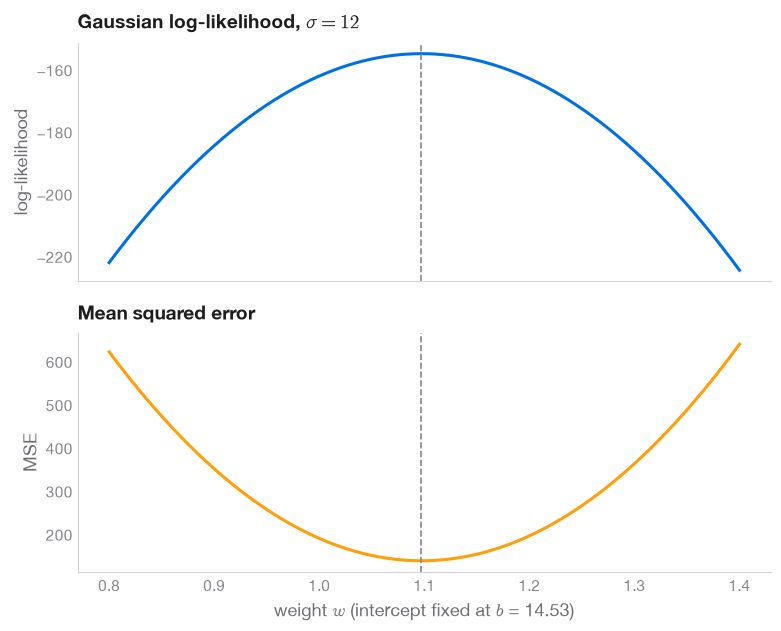

In [17]:
assert w_hat is not None, "Finish Exercise 2.1 first"
w_grid = np.linspace(0.8, 1.4, 601)  # candidate weights with a step of 0.001
log_lik_w = np.array(
    [stats.norm.logpdf(price, loc=b_hat + w * area, scale=12).sum() for w in w_grid]
)
mse_w = np.array([np.mean((price - b_hat - w * area) ** 2) for w in w_grid])
w_best_lik, w_best_mse = w_grid[log_lik_w.argmax()], w_grid[mse_w.argmin()]
print(f"largest log-likelihood at w = {w_best_lik:.3f}")
print(f"smallest MSE at           w = {w_best_mse:.3f}")

fig, (ax_lik, ax_mse) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
ax_lik.plot(w_grid, log_lik_w, color=ACCENT)
ax_lik.set(ylabel="log-likelihood", title=r"Gaussian log-likelihood, $\sigma = 12$")
ax_mse.plot(w_grid, mse_w, color=ORANGE)
ax_mse.set(
    xlabel=r"weight $w$ (intercept fixed at $b$ = " + f"{b_hat:.2f})",
    ylabel="MSE",
    title="Mean squared error",
)
for ax in (ax_lik, ax_mse):
    ax.axvline(w_best_mse, color=INK3, ls="--", lw=1.2)
fig.tight_layout()
plt.show()

The two curves are one parabola, flipped and rescaled, so the best $w$ is the same: maximising the Gaussian likelihood is minimising the squared error. The same reasoning gives an estimate of $\sigma$: fix the fitted line and find the $\sigma$ under which its residuals are most likely.

In [18]:
assert w_hat is not None, "Finish Exercise 2.1 first"
residuals = price - (b_hat + slope_hat * area)
best = optimize.minimize_scalar(
    lambda sigma: -stats.norm.logpdf(residuals, loc=0, scale=sigma).sum(),
    bounds=(1, 50),
    method="bounded",
)
sigma_hat = best.x
print(f"sigma with the largest likelihood: {sigma_hat:.2f}")
print(f"RMSE of the fit:                   {np.sqrt(np.mean(residuals**2)):.2f}")
print("sigma used to generate the data:   12")

sigma with the largest likelihood: 11.68
RMSE of the fit:                   11.68
sigma used to generate the data:   12


The most likely $\sigma$ is the RMSE of the fit, 11.68, close to the 12 behind the data. The page `03_noise_to_mse.html` shows the same idea interactively.

### 3.2 One outlier, two losses

Add one strange flat: 40 m² sold for 300 thousand dollars. It may be a typo or a penthouse. Fit two lines to the 41 flats. The first minimises the squared error (least squares). The second minimises the absolute error (least absolute deviations); `QuantileRegressor(quantile=0.5, alpha=0)` does that.

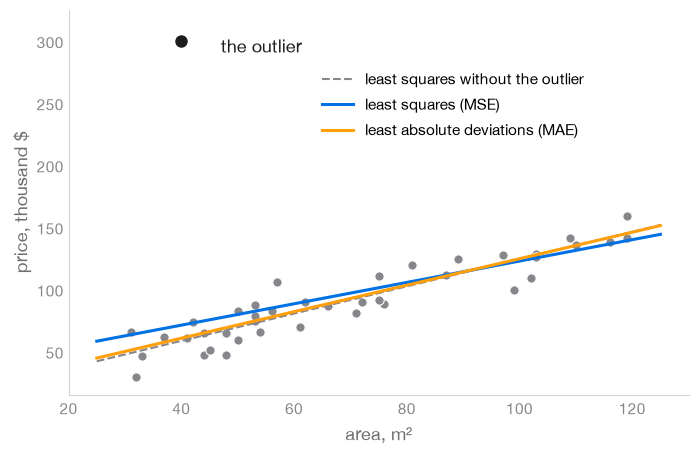

,b,w
"least squares, 40 flats",14.525,1.097
"least squares, 41 flats",36.625,0.860
"least absolute deviations, 41 flats",17.867,1.067


In [19]:
area_out = np.append(area, 40)  # one more flat: 40 m² ...
price_out = np.append(price, 300.0)  # ... sold for 300 thousand dollars
features_out = area_out.reshape(-1, 1)

clean_fit = LinearRegression().fit(area.reshape(-1, 1), price)  # the 40 original flats
squared_fit = LinearRegression().fit(features_out, price_out)
absolute_fit = QuantileRegressor(quantile=0.5, alpha=0, solver="highs").fit(features_out, price_out)

x_line = np.array([[25], [125]])
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(area, price, s=45, color=INK3, edgecolor="white", linewidth=0.8)
ax.scatter([40], [300], s=110, color=INK, edgecolor="white", linewidth=1.5, zorder=5)
ax.annotate("the outlier", (40, 300), xytext=(47, 296), color=INK, va="center")
ax.plot(
    x_line,
    clean_fit.predict(x_line),
    color=INK3,
    ls="--",
    lw=1.5,
    label="least squares without the outlier",
)
ax.plot(x_line, squared_fit.predict(x_line), color=ACCENT, label="least squares (MSE)")
ax.plot(x_line, absolute_fit.predict(x_line), color=ORANGE, label="least absolute deviations (MAE)")
ax.set(xlabel="area, m²", ylabel="price, thousand $", ylim=(15, 325))
ax.legend(loc="upper center", bbox_to_anchor=(0.62, 0.88))
plt.show()

pd.DataFrame(
    {
        "b": [clean_fit.intercept_, squared_fit.intercept_, absolute_fit.intercept_],
        "w": [clean_fit.coef_[0], squared_fit.coef_[0], absolute_fit.coef_[0]],
    },
    index=[
        "least squares, 40 flats",
        "least squares, 41 flats",
        "least absolute deviations, 41 flats",
    ],
).round(3)

One flat out of 41 turns the least squares line: $w$ falls from 1.10 to 0.86 and $b$ rises from 14.5 to 36.6. The least absolute deviations line stays with the other 40 flats.

Squared error is the maximum likelihood loss for Gaussian noise, under which a miss of 240 is practically impossible, so the fit bends towards the outlier to make that miss smaller. Absolute error is the maximum likelihood loss for Laplace noise, which has heavier tails, and it estimates the conditional median of the price where squared error estimates the conditional mean.

## 4. Gradient descent from scratch

The normal equations cost about $n p^2 + p^3$ operations for $p$ features, which is a lot when $p$ is large. Gradient descent needs only the gradient of the loss,

$$\nabla L(\mathbf{w}) = -\frac{2}{n} X^\top (y - X \mathbf{w}),$$

and repeats one step, $\mathbf{w} \leftarrow \mathbf{w} - \eta \, \nabla L(\mathbf{w})$, where $\eta$ is the learning rate. We run it on the flats, where the answer is already known.

### 4.1 The gradient and the loop

In [20]:
def mse_loss(w, X, y):
    """The loss L(w) = (1 / n) * ||y - X w||^2."""
    return np.mean((y - X @ w) ** 2)

**Exercise 4.1.** Write `gradient(w, X, y)` by the formula above.

In [21]:
def gradient(w, X, y):
    """Gradient of the MSE loss at w: -(2 / n) * X^T (y - X w)."""
    return -2 / len(y) * X.T @ (y - X @ w)

A standard test for any gradient is a finite difference: move one weight by a small $h$ and see how much the loss changes, $\frac{\partial L}{\partial w_j} \approx \frac{L(\mathbf{w} + h e_j) - L(\mathbf{w} - h e_j)}{2h}$.

In [22]:
assert X is not None, "Finish Exercise 2.1 first"
w_test = np.array([10.0, 1.0])
grad = gradient(w_test, X, price)
assert grad is not None, "Fill in gradient above"

h = 1e-6
finite_diff = np.array(
    [
        (mse_loss(w_test + h * e_j, X, price) - mse_loss(w_test - h * e_j, X, price)) / (2 * h)
        for e_j in np.eye(2)
    ]
)
assert np.allclose(grad, finite_diff, rtol=1e-5), "The gradient differs from the finite difference"
print("gradient by the formula:", grad.round(3))
print("finite difference:      ", finite_diff.round(3))

gradient by the formula: [  -22.495 -1690.485]
finite difference:       [  -22.495 -1690.485]


The two agree. Look at the components: the derivative along $w$ is about 75 times larger than along $b$, because the area is measured in tens of m² and the column of ones is just 1. The loss is far steeper along $w$ than along $b$.

**Exercise 4.2.** Write the descent loop: `n_steps` times, make a step against the gradient and store the new weights in `path`.

In [23]:
def gradient_descent(X, y, lr, n_steps):
    """Start at zero and take n_steps steps of size lr. Returns every w visited, shape (n_steps + 1, p)."""
    w = np.zeros(X.shape[1])
    path = [w.copy()]
    for _ in range(n_steps):
        w = w - lr * gradient(w, X, y)
        path.append(w.copy())
    return np.array(path)

In [24]:
assert X is not None, "Finish Exercise 2.1 first"
assert gradient(np.zeros(2), X, price) is not None, "Finish Exercise 4.1 first"
first_steps = gradient_descent(X, price, lr=1e-4, n_steps=2)
assert first_steps.shape == (3, 2), "Fill in the loop in gradient_descent above: n_steps + 1 rows"
expected_step = -1e-4 * gradient(np.zeros(2), X, price)
assert np.allclose(first_steps[1], expected_step), "The first step from zero is -lr * gradient(0)"
print(first_steps.round(4))

[[0.     0.    ]
 [0.0181 1.4019]
 [0.0168 1.2689]]


### 4.2 Raw area

First the area as it is, in m², with three learning rates and 50 steps each.

In [25]:
assert X is not None, "Finish Exercise 2.1 first"
raw_paths = {lr: gradient_descent(X, price, lr=lr, n_steps=50) for lr in [1e-3, 2e-4, 1e-4]}
assert len(raw_paths[1e-4]) == 51, "Finish Exercise 4.2 first"
for lr, path in raw_paths.items():
    print(f"learning rate {lr:g}: MSE after 50 steps = {mse_loss(path[-1], X, price):.4g}")

learning rate 0.001: MSE after 50 steps = 5.356e+103
learning rate 0.0002: MSE after 50 steps = 3.139e+11
learning rate 0.0001: MSE after 50 steps = 163.4


With $\eta = 0.001$ and $\eta = 0.0002$ the loss explodes: every step jumps over the minimum and lands further away than it started. $\eta = 0.0001$ is safe. Let it run for 100,000 steps and look at the weights along the way.

In [26]:
assert X is not None, "Finish Exercise 2.1 first"
path_raw = gradient_descent(X, price, lr=1e-4, n_steps=100_000)
assert len(path_raw) == 100_001, "Finish Exercise 4.2 first"
checkpoints = [10, 100, 1_000, 10_000, 100_000]
pd.DataFrame(
    {
        "b": path_raw[checkpoints, 0],
        "w": path_raw[checkpoints, 1],
        "MSE": [mse_loss(path_raw[step], X, price) for step in checkpoints],
    },
    index=pd.Index(checkpoints, name="steps"),
).round(3)

,b,w,MSE
steps,,,
10,0.020,1.280,163.462
100,0.053,1.280,163.338
1000,0.384,1.276,162.126
10000,3.299,1.239,152.641
100000,13.409,1.111,136.636


Ten steps bring the loss down to 163, not far from the minimum of 136.5, and then almost nothing happens. After 10,000 steps $b$ is 3.30, and after 100,000 steps it is 13.41 instead of 14.53. The learning rate must be tiny for the steep direction ($w$), and with a tiny learning rate the flat direction ($b$) crawls.

### 4.3 Standardised area

The cure is the one from week 1: standardise the feature, $z = (x - \bar x) / s_x$. Run the same loop on $z$ with $\eta = 0.1$.

In [27]:
assert X is not None, "Finish Exercise 2.1 first"
area_mean, area_std = area.mean(), area.std()
z = (area - area_mean) / area_std  # standardised area: mean 0, standard deviation 1
X_std = np.column_stack([np.ones(len(z)), z])

path_std = gradient_descent(X_std, price, lr=0.1, n_steps=100)
assert len(path_std) == 101, "Finish Exercise 4.2 first"
# The model b' + w' z is the line (b' - w' * mean / std) + (w' / std) * x in the original units
path_back = np.column_stack(
    [path_std[:, 0] - path_std[:, 1] * area_mean / area_std, path_std[:, 1] / area_std]
)
w_gd = path_back[-1]
steps_needed = int(np.argmax(np.abs(path_back - w_hat).max(axis=1) < 1e-3))

print("gradient descent, 100 steps:", w_gd.round(4))
print("normal equations:           ", w_hat.round(4))
print(f"within 0.001 of the normal equations after {steps_needed} steps")
assert np.allclose(w_gd, w_hat, atol=1e-3), "Gradient descent should reach w_hat"

gradient descent, 100 steps: [14.525   1.0973]
normal equations:            [14.525   1.0973]
within 0.001 of the normal equations after 43 steps


A few dozen steps are enough where 100,000 were not, and the learning rate is a thousand times larger. Two plots show why. The first one is the loss minus its minimum, on a logarithmic axis.

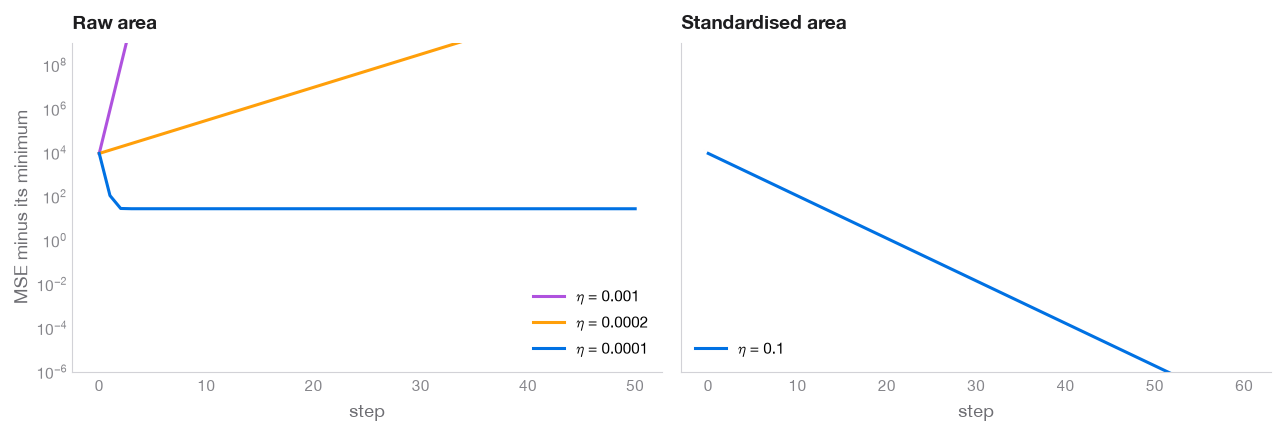

In [28]:
assert X is not None, "Finish Exercise 2.1 first"
assert len(path_raw) == 100_001 and len(path_std) == 101, "Finish Exercise 4.2 first"
min_loss = mse_loss(w_hat, X, price)

fig, (ax_raw, ax_std) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for (lr, path), color in zip(raw_paths.items(), [PURPLE, ORANGE, ACCENT], strict=True):
    excess = np.array([mse_loss(w, X, price) for w in path]) - min_loss
    ax_raw.plot(excess, color=color, label=rf"$\eta$ = {lr:g}")
ax_raw.set(
    xlabel="step", ylabel="MSE minus its minimum", yscale="log", ylim=(1e-6, 1e9), title="Raw area"
)
ax_raw.legend(loc="lower right")

excess = np.array([mse_loss(w, X_std, price) for w in path_std[:61]]) - min_loss
ax_std.plot(np.maximum(excess, 1e-12), color=ACCENT, label=r"$\eta$ = 0.1")
ax_std.set(xlabel="step", title="Standardised area")
ax_std.legend(loc="lower left")
fig.tight_layout()
plt.show()

On the raw area two learning rates blow up and the safe one gets stuck 27 above the minimum. On the standardised area the loss falls by the same factor at every step, a straight line on this axis.

The second plot is the map of the loss over the two weights, with the paths on it.

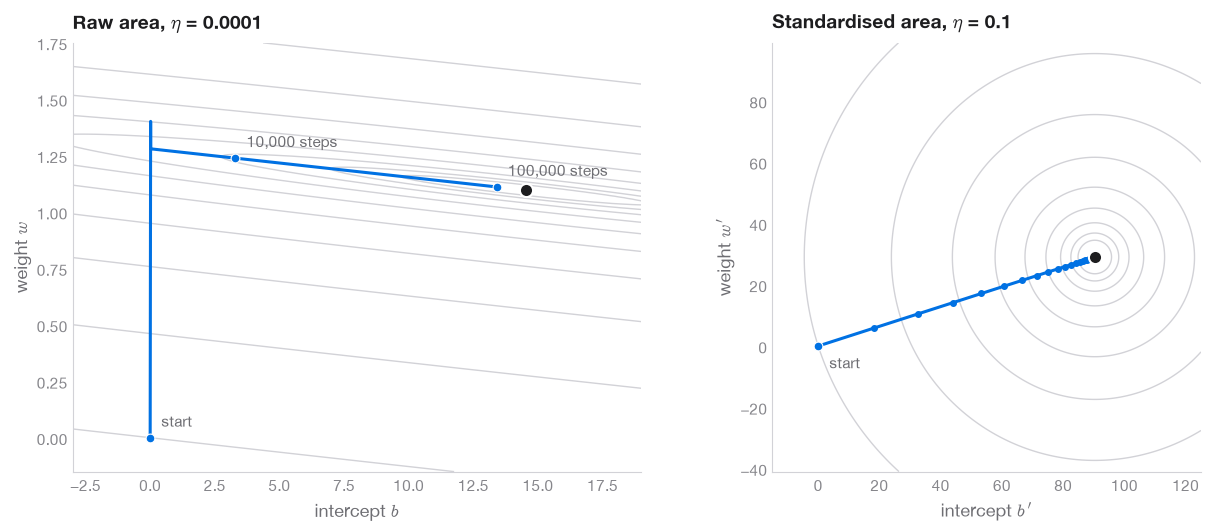

In [29]:
def plot_loss_contours(ax, X, y, w0_range, w1_range, levels):
    """Level lines of the MSE loss over a grid of the two weights."""
    w0, w1 = np.meshgrid(np.linspace(*w0_range, 300), np.linspace(*w1_range, 300))
    predictions = X[:, :1, None] * w0 + X[:, 1:, None] * w1  # shape (n, 300, 300)
    loss = ((y[:, None, None] - predictions) ** 2).mean(axis=0)
    ax.contour(w0, w1, loss, levels=levels, colors=LINE, linewidths=1)


def mark_minimum(ax, w):
    ax.scatter(*w, s=90, color=INK, edgecolor="white", linewidth=1.5, zorder=5)


def mark_step(ax, w, text, offset=(8, 8)):
    """A dot on the path with a label next to it."""
    ax.scatter(*w, s=40, color=ACCENT, edgecolor="white", linewidth=0.8, zorder=4)
    ax.annotate(text, w, xytext=offset, textcoords="offset points", fontsize=11, color=INK2)


assert X is not None, "Finish Exercise 2.1 first"
assert len(path_raw) == 100_001 and len(path_std) == 101, "Finish Exercise 4.2 first"
fig, (ax_raw, ax_std) = plt.subplots(1, 2, figsize=(13, 5.5))

plot_loss_contours(ax_raw, X, price, (-3, 19), (-0.15, 1.75), min_loss + np.geomspace(3, 9000, 10))
ax_raw.plot(path_raw[:, 0], path_raw[:, 1], color=ACCENT)
for step, text in [(0, "start"), (10_000, "10,000 steps"), (100_000, "100,000 steps")]:
    mark_step(ax_raw, path_raw[step], text)
mark_minimum(ax_raw, w_hat)
ax_raw.set(
    xlabel="intercept $b$",
    ylabel="weight $w$",
    xlim=(-3, 19),
    ylim=(-0.15, 1.75),
    title=r"Raw area, $\eta$ = 0.0001",
)

w_std_best = path_std[-1]
plot_loss_contours(
    ax_std, X_std, price, (-15, 125), (-41, 99), min_loss + np.geomspace(30, 9000, 9)
)
ax_std.plot(path_std[:, 0], path_std[:, 1], "o-", ms=4, color=ACCENT)
mark_step(ax_std, path_std[0], "start", offset=(8, -16))
mark_minimum(ax_std, w_std_best)
ax_std.set(
    xlabel="intercept $b'$",
    ylabel="weight $w'$",
    aspect="equal",
    title=r"Standardised area, $\eta$ = 0.1",
)
fig.tight_layout()
plt.show()

The black dot is the minimum. On the raw area the level lines form a long narrow valley. The path reaches its floor in two or three steps and then creeps along it. After standardisation the level lines are circles, the gradient points straight at the minimum, and the path is a straight line. Scaling the features makes the bowl round, which is the main reason to standardise before gradient descent. The page `05_gradient_descent.html` lets you try this yourself.

### 4.4 Mini-batch SGD

On large data even one gradient over all objects is expensive. Stochastic gradient descent (SGD) estimates the gradient on a small random batch and makes a step right away. Here a batch is 8 flats out of 40, so one pass over the data makes 5 steps.

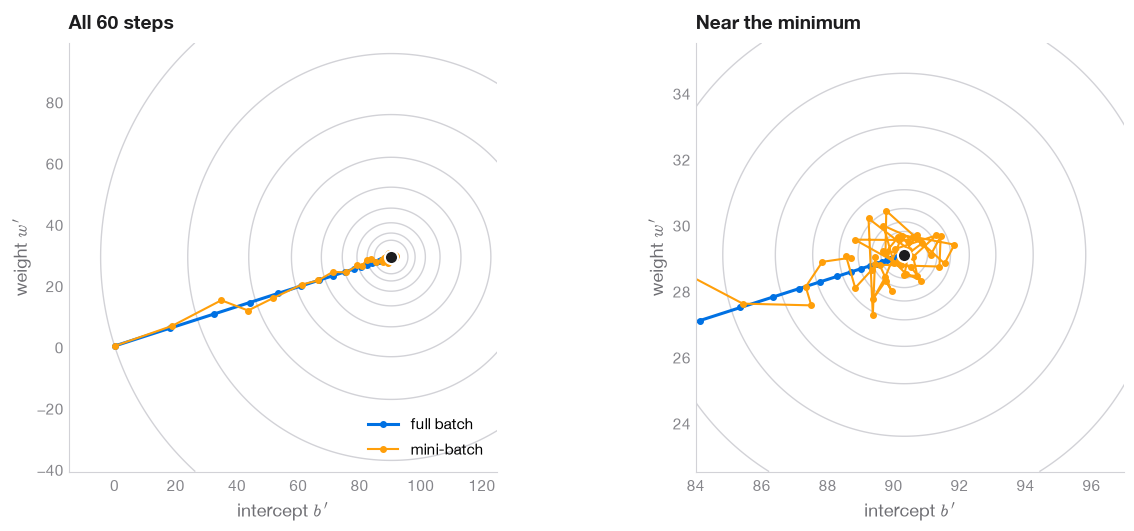

full batch: mean distance to the minimum over the last 20 steps = 0.00
mini-batch: mean distance to the minimum over the last 20 steps = 0.83


In [30]:
def minibatch_sgd(X, y, lr, n_epochs, batch_size, seed):
    """Gradient descent where every step uses the gradient on one random batch."""
    rng = np.random.default_rng(seed)
    w = np.zeros(X.shape[1])
    path = [w.copy()]
    for _ in range(n_epochs):
        order = rng.permutation(len(y))  # a new random order of the objects for every pass
        for start in range(0, len(y), batch_size):
            batch = order[start : start + batch_size]
            w = w - lr * gradient(w, X[batch], y[batch])  # the same formula on 8 flats
            path.append(w.copy())
    return np.array(path)


assert X is not None, "Finish Exercise 2.1 first"
assert len(path_raw) == 100_001 and len(path_std) == 101, "Finish Exercise 4.2 first"
path_sgd = minibatch_sgd(X_std, price, lr=0.1, n_epochs=12, batch_size=8, seed=SEED)
path_full = path_std[: len(path_sgd)]  # the same number of steps of full-batch descent

fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(13, 5.5))
views = [
    (ax_all, (-15, 125), (-41, 99), np.geomspace(30, 9000, 9), "All 60 steps"),
    (ax_zoom, (84, 97), (22.5, 35.5), np.geomspace(0.5, 60, 8), "Near the minimum"),
]
for ax, w0_range, w1_range, levels, title in views:
    plot_loss_contours(ax, X_std, price, w0_range, w1_range, min_loss + levels)
    ax.plot(path_full[:, 0], path_full[:, 1], "o-", ms=4, color=ACCENT, label="full batch")
    ax.plot(path_sgd[:, 0], path_sgd[:, 1], "o-", ms=4, lw=1.5, color=ORANGE, label="mini-batch")
    mark_minimum(ax, w_std_best)
    ax.set(
        xlabel="intercept $b'$",
        ylabel="weight $w'$",
        xlim=w0_range,
        ylim=w1_range,
        aspect="equal",
        title=title,
    )
ax_all.legend(loc="lower right")
fig.tight_layout()
plt.show()

for name, path in [("full batch", path_full), ("mini-batch", path_sgd)]:
    distance = np.linalg.norm(path[-20:] - w_std_best, axis=1).mean()
    print(f"{name}: mean distance to the minimum over the last 20 steps = {distance:.2f}")

The mini-batch path goes the same way, but every step uses a noisy estimate of the gradient, so it wobbles. With a constant learning rate it never settles: it keeps wandering around the minimum, while the full-batch path stops there. In return every step is 5 times cheaper. A smaller learning rate shrinks the wandering. Neural networks are trained this way.

## 5. Several features on real data

Now real data: 442 diabetes patients from a medical study. Ten features were measured at the start: age, sex, body mass index (`bmi`), blood pressure (`bp`) and six blood serum measurements. Among them `s1` is total cholesterol, `s2` is LDL cholesterol and `s3` is HDL cholesterol. The target is a score of how far the disease progressed one year later. The dataset comes with scikit-learn.

In [31]:
diabetes = load_diabetes(as_frame=True, scaled=False)  # bundled with scikit-learn, no download
features, target = diabetes.data, diabetes.target
print(f"{features.shape[0]} patients, {features.shape[1]} features")
print(f"target: from {target.min():.0f} to {target.max():.0f}, mean {target.mean():.1f}")

features.describe().T[["mean", "std", "min", "max"]].round(2)

442 patients, 10 features
target: from 25 to 346, mean 152.1


,mean,std,min,max
age,48.52,13.11,19.00,79.00
sex,1.47,0.50,1.00,2.00
bmi,26.38,4.42,18.00,42.20
bp,94.65,13.83,62.00,133.00
s1,189.14,34.61,97.00,301.00
s2,115.44,30.41,41.60,242.40
s3,49.79,12.93,22.00,99.00
s4,4.07,1.29,2.00,9.09
s5,4.64,0.52,3.26,6.11
s6,91.26,11.50,58.00,124.00


The features have very different scales: `s1` is in the hundreds, `s4` is around 4, and `sex` is coded as 1 and 2.

### 5.1 Split and baseline

The workflow is the one from week 1. Split first, 60/20/20. Fit on train, compare models on validation, open the test set once at the end. And start with a baseline: `DummyRegressor` always predicts the mean target of the training set.

In [32]:
X_trval, X_test, y_trval, y_test = train_test_split(
    features, target, test_size=0.2, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trval, y_trval, test_size=0.25, random_state=SEED
)
print(f"train {len(X_train)}, validation {len(X_val)}, test {len(X_test)}")


def report(model, X_part, y_part):
    """RMSE, MAE and R² of a fitted model on one part of the data."""
    pred = model.predict(X_part)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_part, pred)),
        "MAE": mean_absolute_error(y_part, pred),
        "R²": r2_score(y_part, pred),
    }


val_scores = {}  # model name -> metrics on validation
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
val_scores["baseline: mean of train"] = report(baseline, X_val, y_val)
pd.DataFrame(val_scores).T.round(3)

train 264, validation 89, test 89


,RMSE,MAE,R²
baseline: mean of train,75.639,64.129,-0.044


$R^2$ is slightly below zero, because the mean of train is not exactly the mean of validation. Any useful model must beat an RMSE of 75.6.

### 5.2 Linear regression in a pipeline

**Exercise 5.1.** Build a pipeline of `StandardScaler` and `LinearRegression` with `make_pipeline`, fit it on train and compute its validation scores with `report`.

In [33]:
linreg = make_pipeline(StandardScaler(), LinearRegression())
linreg.fit(X_train, y_train)
linreg_val = report(linreg, X_val, y_val)

In [34]:
assert linreg is not None and linreg_val is not None, "Fill in linreg and linreg_val above"
assert hasattr(linreg, "steps"), "linreg should be a pipeline: make_pipeline(scaler, model)"
baseline_rmse = val_scores["baseline: mean of train"]["RMSE"]
assert linreg_val["RMSE"] < baseline_rmse, "Linear regression should beat the baseline"
assert np.isclose(linreg_val["RMSE"], 51.19, atol=0.05), "Fit on train, then score on validation"
val_scores["linear regression"] = linreg_val
pd.DataFrame(val_scores).T.round(3)

,RMSE,MAE,R²
baseline: mean of train,75.639,64.129,-0.044
linear regression,51.194,42.939,0.522


Linear regression cuts the RMSE from 75.6 to 51.2 and explains about half of the variance. Compare it with the model from week 1: `KNeighborsRegressor` in the same pipeline, with $k$ chosen on validation.

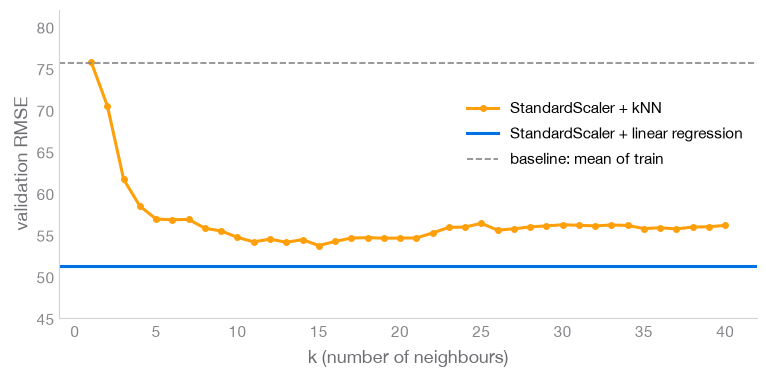

,RMSE,MAE,R²
baseline: mean of train,75.639,64.129,-0.044
linear regression,51.194,42.939,0.522
"kNN, k = 15",53.651,44.210,0.475


In [35]:
assert linreg_val is not None, "Finish Exercise 5.1 first"
k_values = list(range(1, 41))
knn_val_rmse = []
for k in k_values:
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k)).fit(X_train, y_train)
    knn_val_rmse.append(report(knn, X_val, y_val)["RMSE"])
best_k = k_values[int(np.argmin(knn_val_rmse))]
knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=best_k)).fit(X_train, y_train)
val_scores[f"kNN, k = {best_k}"] = report(knn, X_val, y_val)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_values, knn_val_rmse, "o-", ms=4, color=ORANGE, label="StandardScaler + kNN")
ax.axhline(linreg_val["RMSE"], color=ACCENT, label="StandardScaler + linear regression")
ax.axhline(baseline_rmse, color=INK3, ls="--", lw=1.2, label="baseline: mean of train")
ax.set(xlabel="k (number of neighbours)", ylabel="validation RMSE", ylim=(45, 82))
ax.legend(loc="center right", bbox_to_anchor=(1, 0.6))
plt.show()

pd.DataFrame(val_scores).T.round(3)

Both models beat the baseline by a wide margin and are close to each other: an RMSE of 51.2 against 53.7 on 89 patients is within the noise of this split. The linear model gets there with 11 numbers that can be read, while kNN keeps all 264 training patients.

### 5.3 Reading the weights

After standardisation every feature has a standard deviation of 1. A weight then says how much the prediction changes when its feature grows by one standard deviation and the others stay fixed, so the weights can be compared with each other.

intercept: 149.8, mean target on train: 149.8


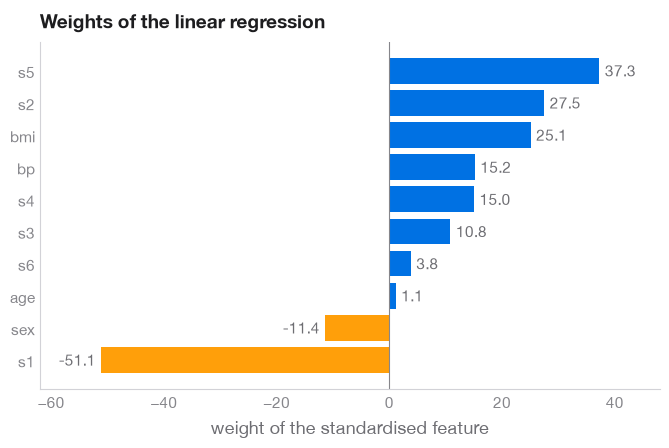

In [36]:
assert linreg is not None, "Finish Exercise 5.1 first"
coefs = pd.Series(linreg[-1].coef_, index=features.columns).sort_values()
print(f"intercept: {linreg[-1].intercept_:.1f}, mean target on train: {y_train.mean():.1f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(
    coefs.index, coefs.values, color=[ACCENT if value > 0 else ORANGE for value in coefs]
)
ax.bar_label(bars, fmt="%.1f", padding=4, color=INK2, fontsize=11)
ax.axvline(0, color=INK3, lw=0.8)
ax.set(
    xlabel="weight of the standardised feature",
    xlim=(-62, 48),
    title="Weights of the linear regression",
)
plt.show()

`bmi` has a weight of 25.1: for a patient whose body mass index is one standard deviation (4.4 kg/m²) higher, with the other features equal, the prediction is 25 points higher. In the original units that is 5.7 points per kg/m². `s5` and `bp` push the prediction up as well. The intercept is the mean target on train, because standardised features have zero mean.

The largest weight by size is negative. It belongs to `s1`, total cholesterol ($-51.1$), while `s2`, LDL cholesterol, gets $+27.5$. Read literally, more total cholesterol slows the disease down and more LDL cholesterol speeds it up. Before believing that, look at how the two features relate.

### 5.4 Features that repeat each other

LDL cholesterol is a part of total cholesterol, so `s1` and `s2` measure almost the same thing. Look at the correlations between the features on train.

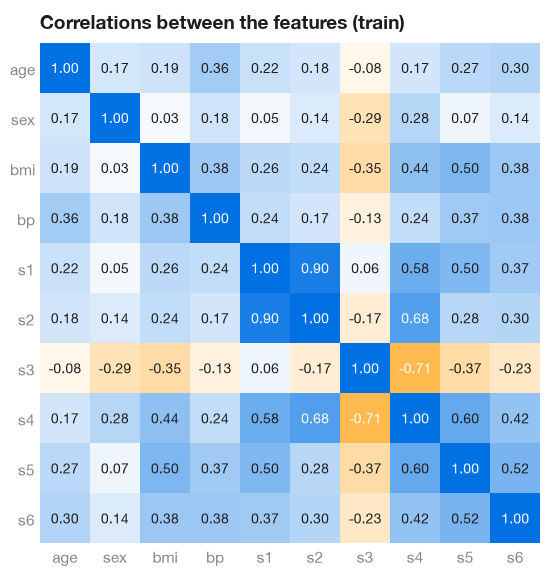

In [37]:
corr = X_train.corr()
corr_cmap = LinearSegmentedColormap.from_list("orange_white_blue", [ORANGE, "white", ACCENT])

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(corr, cmap=corr_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        color = "white" if abs(value) > 0.65 else INK
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=10, color=color)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Correlations between the features (train)")
plt.show()

The correlation between `s1` and `s2` is 0.90. When two columns carry nearly the same information, the data cannot tell how to share the weight between them: raise one weight, lower the other, and the predictions hardly change.

To see what that does to the weights, refit the model on 200 bootstrap resamples of the training set. Each resample is 264 patients drawn with replacement, a slightly different dataset from the same source.

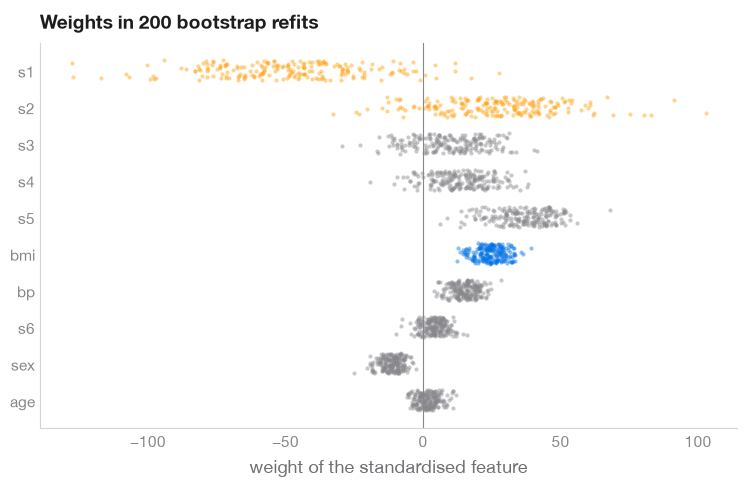

condition number of X^T X: 506, without s1: 53
correlation between the weights of s1 and s2: -0.96


,mean,std,min,max
s1,-49.1,27.0,-127.8,27.6
s2,26.5,21.6,-32.7,102.7
s3,9.5,12.5,-29.5,41.5
s4,13.8,10.2,-19.3,38.2
s5,36.4,10.1,6.3,68.1
bmi,24.7,5.0,12.4,39.4
bp,15.1,4.4,3.9,28.3
s6,4.0,4.1,-9.7,16.1
sex,-11.4,3.6,-25.1,-2.7
age,1.7,3.6,-5.7,11.8


In [38]:
rng = np.random.default_rng(SEED)
boot_coefs = []
for _ in range(200):
    rows = rng.integers(0, len(X_train), size=len(X_train))  # 264 row numbers, with repeats
    model = make_pipeline(StandardScaler(), LinearRegression())
    model.fit(X_train.iloc[rows], y_train.iloc[rows])
    boot_coefs.append(model[-1].coef_)
boot_coefs = pd.DataFrame(boot_coefs, columns=features.columns)
order = boot_coefs.std().sort_values().index  # from the most stable weight to the least stable

fig, ax = plt.subplots(figsize=(9, 5))
jitter = np.random.default_rng(SEED).uniform(-0.28, 0.28, size=len(boot_coefs))
for position, name in enumerate(order):
    color = ORANGE if name in ("s1", "s2") else ACCENT if name == "bmi" else INK3
    ax.scatter(boot_coefs[name], position + jitter, s=9, color=color, alpha=0.45, linewidth=0)
ax.axvline(0, color=INK3, lw=0.8)
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="weight of the standardised feature", title="Weights in 200 bootstrap refits")
plt.show()

gram = StandardScaler().fit_transform(X_train)
gram = gram.T @ gram  # the matrix X^T X of the normal equations, for standardised features
gram_no_s1 = StandardScaler().fit_transform(X_train.drop(columns="s1"))
gram_no_s1 = gram_no_s1.T @ gram_no_s1
cond, cond_no_s1 = np.linalg.cond(gram), np.linalg.cond(gram_no_s1)
print(f"condition number of X^T X: {cond:.0f}, without s1: {cond_no_s1:.0f}")
weight_corr = boot_coefs["s1"].corr(boot_coefs["s2"])
print(f"correlation between the weights of s1 and s2: {weight_corr:.2f}")
boot_coefs[order[::-1]].agg(["mean", "std", "min", "max"]).T.round(1)

The weight of `bmi` stays between 12 and 39 in all 200 refits. The weight of `s1` runs from $-128$ to $+28$ and the weight of `s2` from $-33$ to $+103$, so the data does not even fix their signs. The two move against each other (correlation $-0.96$): when one goes up, the other goes down. The answer to the cholesterol question is that these two weights cannot be read one at a time.

The condition number of $X^\top X$ measures the same trouble: the larger it is, the closer the matrix is to singular and the more the solution reacts to small changes in the data. Here it is 506, and 53 without `s1`. Regularisation, later in the course, fixes this. The page `06_correlated_features.html` shows the same effect on two features.

### 5.5 Residuals

Least squares is maximum likelihood under three assumptions about the noise: zero mean, the same variance everywhere, independent errors. The residuals $y_i - \hat y_i$ are our estimate of the noise, so look at them.

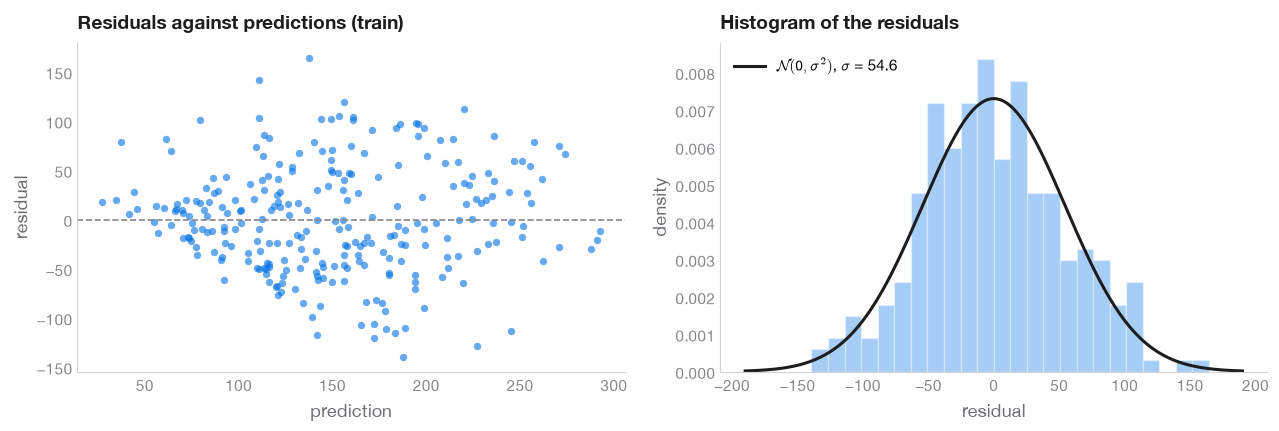

std of the residuals for low, middle and high predictions: [41.  59.4 61.7]


In [39]:
assert linreg is not None, "Finish Exercise 5.1 first"
train_pred = linreg.predict(X_train)
train_residuals = y_train - train_pred
noise_std = np.sqrt(np.mean(train_residuals**2))  # the maximum likelihood estimate of sigma

fig, (ax_scatter, ax_hist) = plt.subplots(1, 2, figsize=(13, 4.5))
ax_scatter.scatter(train_pred, train_residuals, s=28, color=ACCENT, alpha=0.6, linewidth=0)
ax_scatter.axhline(0, color=INK3, ls="--", lw=1.2)
ax_scatter.set(
    xlabel="prediction", ylabel="residual", title="Residuals against predictions (train)"
)

r_grid = np.linspace(-190, 190, 300)
ax_hist.hist(train_residuals, bins=24, density=True, color=ACCENT, alpha=0.35, edgecolor="white")
ax_hist.plot(
    r_grid,
    stats.norm.pdf(r_grid, 0, noise_std),
    color=INK,
    label=rf"$\mathcal{{N}}(0, \sigma^2)$, $\sigma$ = {noise_std:.1f}",
)
ax_hist.set(xlabel="residual", ylabel="density", title="Histogram of the residuals")
ax_hist.legend(loc="upper left")
fig.tight_layout()
plt.show()

thirds = np.array_split(np.argsort(train_pred), 3)  # patients with low, middle and high predictions
spread = [train_residuals.iloc[part].std() for part in thirds]
print("std of the residuals for low, middle and high predictions:", np.round(spread, 1))

The histogram is roughly bell-shaped and centred at zero, so the Gaussian model of the noise is not far off. The spread is not constant, though: the residuals have a standard deviation of 41 where the prediction is low and about 60 where it is high. One reason is that the target is never below 25, so where the prediction is low the residuals cannot be very negative. Least squares still gives a reasonable line, but "the same $\sigma$ everywhere" holds only roughly on this data.

### 5.6 The test set, once

On validation we compared two models. We keep the linear one: it is simpler and kNN did no better. Nothing else will be tuned, so the test set can be opened.

**Exercise 5.2.** Fit the same pipeline as in Exercise 5.1 on train and validation together (`X_trval`, `y_trval`), and compute its scores on the test set with `report`. Do it once.

In [40]:
final_model = make_pipeline(StandardScaler(), LinearRegression()).fit(X_trval, y_trval)
test_scores = report(final_model, X_test, y_test)

In [41]:
assert linreg_val is not None, "Finish Exercise 5.1 first"
assert final_model is not None, "Fill in final_model above"
assert test_scores is not None, "Fill in test_scores above"
assert np.isclose(test_scores["RMSE"], 53.85, atol=0.05), "Fit on X_trval, score on the test set"
baseline_trval = DummyRegressor(strategy="mean").fit(X_trval, y_trval)
pd.DataFrame(
    {
        "linear regression, validation": linreg_val,
        "linear regression, test": test_scores,
        "baseline: mean, test": report(baseline_trval, X_test, y_test),
    }
).T.round(3)

,RMSE,MAE,R²
"linear regression, validation",51.194,42.939,0.522
"linear regression, test",53.853,42.794,0.453
"baseline: mean, test",73.222,64.006,-0.012


Validation said 51.2, the test set says 53.9. With 89 patients in each part a gap of this size is ordinary noise. The test number is the one to report, next to the baseline's 73.2 on the same patients.

## 6. What to remember

- Maximum likelihood picks the parameters under which the observed data is most likely. In practice we minimise the negative log-likelihood, because a product of many probabilities underflows.
- Gaussian noise plus maximum likelihood is least squares, and the estimate of $\sigma$ is the RMSE of the fit. Laplace noise gives the absolute error, which resists outliers.
- Least squares has a closed form, $X^\top X \mathbf{w} = X^\top y$. Solve it with `np.linalg.solve` or `np.linalg.lstsq` and leave the inverse alone.
- Gradient descent needs only the gradient. It is fast when the features are standardised and painfully slow when they are not.
- Report RMSE, MAE and $R^2$ next to a baseline. Weights of standardised features can be compared, but the weights of correlated features are unstable.

## Try at home

1. The five students from week 1 have marks in statistics and Python of (5, 4), (4, 5), (5, 5), (3, 4), (3, 3) and marks in ML of 5, 4, 5, 5, 2. Solve the normal equations without a column of ones and check that you get the weights 0.37 and 0.65 from lecture 1. Then add the column of ones. How much does the MSE change?
2. On the raw area, find by trial the largest learning rate that still converges. Compare it with $2 / \lambda_{\max}$, where $\lambda_{\max}$ is the largest eigenvalue of $\frac{2}{n} X^\top X$ (`np.linalg.eigvalsh`). Then do the same for the standardised area.
3. In the diabetes data, drop `s1` and fit the pipeline again. How much do the validation scores change, and what happens to the weight of `s2`?